# Extensions: segment coverage, a tested monitoring rule, and coverage versus calibration age
Real data only (Lending Club wide file + Prosper snapshot). **Run All** (about 5 minutes); the last cell zips everything to `Desktop/Q2/outputs_extensions.zip`.

| part | what it adds to the paper |
|---|---|
| E1 | **Coverage by borrower segment** (grade, purpose, income, FICO, amount, DTI, home ownership, ...) with Wilson intervals, the worst segment, and a simple **group-conditional fix** (separate thresholds per grade group) |
| E2 | **A tested monitoring rule**: does the monthly gap between realised and predicted default rates track coverage, and would a trailing-gap alarm have warned in time? (Prosper also with exact label availability: how misleading is the gap computed from known labels only?) |
| E3 | **Coverage versus calibration age**: how fast does static coverage move away from nominal after the calibration year, month by month? |

Lending Club file: found automatically (or set `MANUAL_WIDE` in the Lending Club cell). No payments file is needed.

In [11]:
import os, sys, subprocess, importlib, warnings, json, hashlib, time, traceback, contextlib, shutil, urllib.request
from pathlib import Path
def ensure(pkg, mod=None):
    try: importlib.import_module(mod or pkg)
    except ImportError: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
ensure('lightgbm'); ensure('statsmodels'); ensure('scikit-learn', 'sklearn')
import numpy as np, pandas as pd, lightgbm as lgb, matplotlib
matplotlib.use(os.environ.get('MPL_BACKEND', matplotlib.get_backend()))
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.proportion import proportion_confint
warnings.filterwarnings('ignore'); plt.style.use('seaborn-v0_8-whitegrid')
def find_q2():
    if os.environ.get('Q2_DIR'): return Path(os.environ['Q2_DIR'])
    home = Path.home()
    for d in [home/'Desktop', home/'OneDrive'/'Desktop', *sorted(home.glob('OneDrive*/Desktop'))]:
        if (d/'Q2').is_dir(): return d/'Q2'
Q2 = find_q2(); assert Q2 is not None, "No 'Q2' folder on the Desktop; set Q2 = Path(r'...') here."
OUT = Q2/'outputs_extensions'; TAB, FIG = OUT/'tables', OUT/'figures'; TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(exist_ok=True)
SEED, ALPHA = 42, 0.10; FAILED = []; T0 = time.time()
@contextlib.contextmanager
def section(name):
    t = time.time(); print(f"\n{'=' * 10} {name} {'=' * 10}")
    try: yield
    except Exception:
        FAILED.append(name); print(f"!!! SECTION FAILED: {name}"); traceback.print_exc()
    finally: print(f"[{name}: {time.time() - t:.0f}s | total {(time.time() - T0) / 60:.1f} min]")
def save(df, name): df.round(5).to_csv(TAB/f'{name}.csv', index=False)
def savefig(name):
    for ext in ('png', 'pdf'): plt.savefig(FIG/f'{name}.{ext}', dpi=180, bbox_inches='tight')
def conf_q(scores, alpha):
    s = np.sort(np.asarray(scores)); n = len(s); k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else s[k - 1]
def true_scores(p, y): return np.where(y == 1, 1 - p, p)
def conformal_sets(p, y, ca, alpha=ALPHA, nbin=5):
    sc = true_scores(p, y); q = conf_q(sc[ca], alpha); q0, q1 = conf_q(sc[ca & (y == 0)], alpha), conf_q(sc[ca & (y == 1)], alpha)
    edges = np.quantile(p[ca], np.linspace(0, 1, nbin + 1)[1:-1]); b = np.digitize(p, edges)
    qb = np.array([conf_q(sc[ca & (b == k)], alpha) for k in range(nbin)])[b]
    return {'static': np.column_stack([p <= q, (1 - p) <= q]), 'class-conditional': np.column_stack([p <= q0, (1 - p) <= q1]), 'bin-conditional': np.column_stack([p <= qb, (1 - p) <= qb])}
def cov_stats(S, y):
    hit = S[np.arange(len(y)), y]; ap, rj = S[:, 0] & ~S[:, 1], S[:, 1] & ~S[:, 0]
    return dict(cov=hit.mean(), cov_default=hit[y == 1].mean() if (y == 1).any() else np.nan, size=S.sum(1).mean(), share_review=1 - ap.mean() - rj.mean(), share_reject_only=rj.mean())
def tiers(S): ap = S[:, 0] & ~S[:, 1]; rj = S[:, 1] & ~S[:, 0]; return ap, ~(ap | rj), rj
def wilson(k, n): return proportion_confint(int(k), int(n), method='wilson')
print("Q2:", Q2)

Q2: /Users/author/Desktop/Q2


In [12]:
# ---------- 0. extraction: Prosper file -> analysis frame ----------
with section('0. data'):
    PF = Q2/'extra_data'/'prosper'/'prosperLoanData.csv'; PF.parent.mkdir(parents=True, exist_ok=True)
    if not PF.exists():
        url = "https://raw.githubusercontent.com/chukwume/prosperloandata/master/prosperLoanData.csv"; print("downloading", url)
        urllib.request.urlretrieve(url, PF)
    sha = hashlib.sha256(PF.read_bytes()).hexdigest(); print("SHA-256:", sha, "| matches expected:", sha == 'fce13408ac22e8201363e71e1a16d9795305f4aaf8c0f67efcd80424bc5b9e02')
    d = pd.read_csv(PF, low_memory=False); print("raw rows:", len(d))
    dt = lambda c: pd.to_datetime(d[c], format='ISO8601', errors='coerce')
    d['orig'], d['closed'], d['listed'], d['first_cl'] = dt('LoanOriginationDate'), dt('ClosedDate'), dt('ListingCreationDate'), dt('FirstRecordedCreditLine')
    keep = d['LoanStatus'].isin(['Completed', 'Chargedoff', 'Defaulted']) & (d['Term'] == 36) & (d['orig'] >= '2006-01-01') & (d['orig'] <= '2011-03-31')
    f = d[keep].sort_values('orig', kind='stable').reset_index(drop=True); print(f"resolved 36-month loans, issued 2006 to Mar-2011: {len(f):,}  default rate {f['LoanStatus'].ne('Completed').mean():.2%}")
    f['default'] = f['LoanStatus'].ne('Completed').astype(int); f['year'], f['month'] = f['orig'].dt.year, f['orig'].dt.month
    f['tm'] = (f['year'] - 2006) * 12 + f['month']; f['reveal'] = np.maximum(((f['closed'].dt.year - 2006) * 12 + f['closed'].dt.month).values, f['tm'].values + 1)
    f['funded'] = f['LoanOriginalAmount'].astype(float)
    f['profit'] = f['LP_InterestandFees'] + f['LP_ServiceFees'] + f['LP_CollectionFees'] + f['LP_NonPrincipalRecoverypayments'] - f['LP_NetPrincipalLoss']
    f['roi'] = f['profit'] / f['funded']
    gmap = {'AA': 0, 'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'HR': 6}
    f['grade_ord'] = f['ProsperRating (Alpha)'].map(gmap).fillna(f['CreditGrade'].map(gmap))
    f['fico'] = (f['CreditScoreRangeLower'] + f['CreditScoreRangeUpper']) / 2; f['dti'] = f['DebtToIncomeRatio'].clip(0, 1.5)
    f['log_income'] = np.log1p(f['StatedMonthlyIncome'].clip(0, 100000)); f['log_amount'] = np.log1p(f['funded']); f['rate'] = f['BorrowerRate']
    f['homeowner'] = f['IsBorrowerHomeowner'].astype(float); f['employment'] = f['EmploymentStatus'].fillna('NA'); f['purpose'] = f['ListingCategory (numeric)'].astype(str); f['state'] = f['BorrowerState'].fillna('NA')
    f['bankcard_util'] = f['BankcardUtilization'].clip(0, 2); f['log_revbal'] = np.log1p(f['RevolvingCreditBalance'].clip(lower=0)); f['log_amt_delinq'] = np.log1p(f['AmountDelinquent'].clip(lower=0)); f['log_avail_bc'] = np.log1p(f['AvailableBankcardCredit'].clip(lower=0))
    f['credit_hist_yrs'] = (f['listed'] - f['first_cl']).dt.days / 365.25
    for a, b in (('open_lines', 'OpenCreditLines'), ('curr_delinq', 'CurrentDelinquencies'), ('delinq_7y', 'DelinquenciesLast7Years'), ('pub_rec_10y', 'PublicRecordsLast10Years'), ('inq_6m', 'InquiriesLast6Months'),
                 ('total_inq', 'TotalInquiries'), ('total_trades', 'TotalTrades'), ('never_delinq_pct', 'TradesNeverDelinquent (percentage)'), ('curr_lines', 'CurrentCreditLines')): f[a] = f[b]
    f['prior_prosper_loans'] = f['TotalProsperLoans'].fillna(0)
    CORE = ['fico', 'dti', 'log_income', 'log_amount', 'homeowner', 'inq_6m', 'bankcard_util', 'curr_delinq', 'open_lines', 'log_revbal']
    BUREAU = ['log_amt_delinq', 'delinq_7y', 'pub_rec_10y', 'total_inq', 'log_avail_bc', 'total_trades', 'never_delinq_pct', 'credit_hist_yrs', 'curr_lines', 'prior_prosper_loans']
    miss = f[CORE + BUREAU + ['rate', 'grade_ord']].isna().groupby(f['year']).mean().T.round(2); print("\nMissing share by year:"); print(miss.to_string())
    drop = [c for c in CORE + BUREAU if f.loc[f.year <= 2008, c].isna().mean() > 0.5]; CORE = [c for c in CORE if c not in drop]; BUREAU = [c for c in BUREAU if c not in drop]; print("dropped (mostly missing in training years):", drop)
    FS = {'P0 with lender rate': (CORE + ['rate'], ['employment', 'purpose']), 'P1 no lender score': (CORE, ['employment', 'purpose']),
          'P3 applicant-only rich': (CORE + BUREAU, ['employment', 'purpose', 'state']), 'P4 everything': (CORE + BUREAU + ['rate', 'grade_ord'], ['employment', 'purpose', 'state'])}
    Xc = {k: pd.get_dummies(f[n + c], columns=c, drop_first=True) for k, (n, c) in FS.items()}
    y, yr, tm, pi, fund, roi = f['default'].values, f['year'].values, f['tm'].values, f['profit'].values, f['funded'].values, f['roi'].values
    T1 = f.groupby('year').agg(N=('default', 'size'), default_rate=('default', 'mean'), mean_rate=('rate', 'mean'), mean_fico=('fico', 'mean'), mean_dti=('dti', 'mean'), mean_amount=('funded', 'mean'),
                               profit_per_loan=('profit', 'mean'), return_on_funded=('profit', lambda s: s.sum() / f.loc[s.index, 'funded'].sum())).reset_index(); save(T1, 'P1_data_summary_by_year'); print(); print(T1.round(3).to_string(index=False))
    g = f.groupby('default').apply(lambda x: x['profit'].sum() / x['funded'].sum()); print(f"\nprofit per $ funded: repaid {g[0]:+.3f}, default {g[1]:+.3f} -> break-even default probability ~ {g[0] / (g[0] - g[1]):.1%}")
    save(pd.DataFrame([dict(profit_per_dollar_repaid=g[0], profit_per_dollar_default=g[1], breakeven_default_prob=g[0] / (g[0] - g[1]))]), 'P2_breakeven')
    lag = ((f['reveal'] - f['tm']))
    desc = pd.DataFrame({'outcome': np.where(y == 1, 'default', 'repaid'), 'months_to_label': lag}).groupby('outcome')['months_to_label'].describe(percentiles=[.1, .25, .5, .75, .9]).reset_index(); save(desc, 'P3_label_lag_by_outcome'); print("\nMonths from origination to label known (exact ClosedDate):"); print(desc.round(1).to_string(index=False))


========== 0. data ==========
downloading https://raw.githubusercontent.com/chukwume/prosperloandata/master/prosperLoanData.csv
SHA-256: fce13408ac22e8201363e71e1a16d9795305f4aaf8c0f67efcd80424bc5b9e02 | matches expected: True
raw rows: 113937
resolved 36-month loans, issued 2006 to Mar-2011: 37,934  default rate 32.15%

Missing share by year:
year                 2006  2007  2008  2009  2010  2011
fico                 0.10  0.00  0.00  0.00  0.00   0.0
dti                  0.01  0.02  0.08  0.10  0.12   0.1
log_income           0.00  0.00  0.00  0.00  0.00   0.0
log_amount           0.00  0.00  0.00  0.00  0.00   0.0
homeowner            0.00  0.00  0.00  0.00  0.00   0.0
inq_6m               0.11  0.00  0.00  0.00  0.00   0.0
bankcard_util        1.00  0.15  0.00  0.00  0.00   0.0
curr_delinq          0.11  0.00  0.00  0.00  0.00   0.0
open_lines           1.00  0.15  0.00  0.00  0.00   0.0
log_revbal           1.00  0.15  0.00  0.00  0.00   0.0
log_amt_delinq       1.00  0.15  0.00

In [13]:
# ---------- 1. model zoo and temporal designs ----------
LGB_REG = dict(n_estimators=250, learning_rate=0.03, num_leaves=15, max_depth=4, min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=10.0, random_state=SEED, verbose=-1)
MODELS = ['LGBM default', 'LGBM regularised', 'Logistic (L2)']
def fit_predict(kind, X, mtr):
    if kind == 'LGBM default': m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=SEED, verbose=-1)
    elif kind == 'LGBM regularised': m = lgb.LGBMClassifier(**LGB_REG)
    else:
        Xf = X.astype('float32'); miss_ = [c for c in Xf.columns if Xf.loc[mtr, c].isna().any()]; ind = Xf[miss_].isna().astype('float32').add_suffix('_na')
        Xf = pd.concat([Xf.fillna(Xf.loc[mtr].median().fillna(0)), ind], axis=1); mu, sd = Xf.loc[mtr].mean().fillna(0), Xf.loc[mtr].std().replace(0, 1).fillna(1); Z = np.nan_to_num(((Xf - mu) / sd).values)
        return LogisticRegression(C=0.1, max_iter=3000).fit(Z[mtr], y[mtr]).predict_proba(Z)[:, 1]
    return m.fit(X[mtr], y[mtr]).predict_proba(X)[:, 1]
def fit_reg(X, target, mtr): return lgb.LGBMRegressor(**LGB_REG).fit(X[mtr], target[mtr]).predict(X)
DESIGNS = {'B': dict(label='B: train 2006-08, calibrate 2009, test 2010-11Q1', train_end=2008, ca=2009, tests=[2010, 2011]),
           'A': dict(label='A: train 2006-07, calibrate 2008, test 2009-11Q1', train_end=2007, ca=2008, tests=[2009, 2010, 2011])}
tlabel = lambda yy: '2011Q1' if yy == 2011 else str(yy)


In [14]:
# ---------- Lending Club frame ----------
AUD = []
def audit(part, item, value, note=''): AUD.append(dict(part=part, item=item, value=value, note=note))
# ---- If the automatic search below cannot find your files, paste their FULL paths here (keep the quotes), e.g.
#      MANUAL_WIDE = '/Users/yourname/Downloads/lending_club_36m_wide.csv'
MANUAL_WIDE = ''
MANUAL_PAYMENTS = ''
HAS_LC = False; HAS_LCPAY = False
def find_file(patterns, extra_roots=()):
    for root in [Q2, *extra_roots, Q2.parent, Path.home()/'Downloads', Path.home()/'Documents']:
        if not Path(root).exists(): continue
        for pat in patterns:
            hits = [h for h in sorted(Path(root).rglob(pat)) if h.is_file()]
            if hits: return hits[0]
    return None
with section('LC load'):
    WIDE = Path(MANUAL_WIDE) if MANUAL_WIDE else find_file(['lending_club_36m_wide*.csv'])
    if WIDE is None: raise FileNotFoundError("lending_club_36m_wide.csv not found under Desktop/Q2, Desktop, Downloads or Documents. Put it in Desktop/Q2/extra_data/ (it is the file written by Extract_Extra_Data.ipynb) and rerun.")
    print("Lending Club wide file:", WIDE)
    W = pd.read_csv(WIDE, dtype={'id': str}); LC = W[W.year <= 2015].reset_index(drop=True)
    PAYF = Path(MANUAL_PAYMENTS) if MANUAL_PAYMENTS else find_file(['payments*.csv']); HAS_LCPAY = False
    if PAYF is not None:
        _p = pd.read_csv(PAYF, dtype={'id': str})
        if {'id', 'total_pymnt'} <= set(_p.columns):
            LC = LC.merge(_p[['id', 'total_pymnt']].drop_duplicates('id'), on='id', how='left'); LC['profit'] = LC['total_pymnt'] - LC['funded_amnt']; HAS_LCPAY = True; print("payments file:", PAYF)
    if not HAS_LCPAY: print("!! payments.csv not found or lacks id/total_pymnt: the Lending Club profit checks will be skipped (everything else still runs)")
    yL, yrL = LC['default'].values, LC['year'].values
    LC_NUM = ['loan_amnt', 'annual_inc', 'dti', 'fico_score', 'revol_util', 'delinq_2yrs', 'emp_length_yrs', 'int_rate']; LC_CAT = ['home_ownership', 'verification_status', 'purpose']
    XL = pd.get_dummies(LC[LC_NUM + LC_CAT], columns=LC_CAT, drop_first=True); XL1 = XL.drop(columns=['int_rate'])
    def fit_lgb(kind, X, mtr, seed=42):
        if kind == 'default': m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=seed, verbose=-1)
        else: m = lgb.LGBMClassifier(**{**LGB_REG, 'random_state': seed, 'min_child_samples': 200})
        return m.fit(X[mtr], yL[mtr]).predict_proba(X)[:, 1]
    HAS_LC = True; print(f"Lending Club frame: {len(LC):,} loans; payments available: {HAS_LCPAY}")




========== LC load ==========
Lending Club wide file: /Users/author/Desktop/Q2/lending_club_36m_wide.csv
!! payments.csv not found or lacks id/total_pymnt: the Lending Club profit checks will be skipped (everything else still runs)
Lending Club frame: 582,113 loans; payments available: False
[LC load: 2s | total 2.1 min]


In [15]:
# ---------- stop here with a clear message if the Lending Club data were not loaded ----------
if not HAS_LC:
    raise RuntimeError("STOP: the Lending Club file was not loaded (see the message printed under 'LC load' above). Fix: put lending_club_36m_wide.csv in Desktop/Q2/extra_data/, or set MANUAL_WIDE = '/full/path/lending_club_36m_wide.csv' near the top of the previous cell, then run all again. Nothing below can run without it.")
print('Lending Club data loaded - continuing.')


Lending Club data loaded - continuing.


In [16]:
# ---------- baseline predictions and shared helpers ----------
pL = fit_lgb('default', XL, yrL <= 2011); caL = yrL == 2012; teL = yrL >= 2013
X0 = Xc['P0 with lender rate']; PD = {'B': dict(ca=2009, tr=2008, tests=[2010, 2011]), 'A': dict(ca=2008, tr=2007, tests=[2009, 2010, 2011])}
pP = {k: fit_predict('LGBM default', X0, yr <= v['tr']) for k, v in PD.items()}
def seg_table(port, design, segs, p, yy, ca, te, minN=150):
    S = conformal_sets(p, yy, ca); rows = []
    for sname, ser in segs.items():
        ser = pd.Series(np.asarray(ser)).astype(str).values
        for v in pd.unique(ser):
            m = te & (ser == v)
            if m.sum() < minN: continue
            cs = cov_stats(S['static'][m], yy[m]); cc = cov_stats(S['class-conditional'][m], yy[m]); cb = cov_stats(S['bin-conditional'][m], yy[m]); lo, hi = wilson(cs['cov'] * m.sum(), m.sum())
            rows.append(dict(portfolio=port, design=design, segment=sname, value=v, N=int(m.sum()), actual_default=yy[m].mean(), mean_pred=p[m].mean(), static_cov=cs['cov'], ci_lo=lo, ci_hi=hi, static_cov_default=cs['cov_default'],
                             classcond_cov=cc['cov'], bin_cov=cb['cov'], static_size=cs['size'], share_reject_only=cs['share_reject_only']))
    return pd.DataFrame(rows)
def groupcond_cov(p, yy, ca, te, groups, minN=150):
    sc = true_scores(p, yy); g = pd.Series(np.asarray(groups)).astype(str).values; hit = np.zeros(len(yy), bool); rows = []
    for v in pd.unique(g):
        q = conf_q(sc[ca & (g == v)], ALPHA) if (ca & (g == v)).sum() > 50 else conf_q(sc[ca], ALPHA)
        hit[g == v] = sc[g == v] <= q
    S = conformal_sets(p, yy, ca)['static']; hs = S[np.arange(len(yy)), yy]
    for v in pd.unique(g):
        m = te & (g == v)
        if m.sum() >= minN: rows.append(dict(group=v, N=int(m.sum()), static_cov=hs[m].mean(), groupcond_cov=hit[m].mean()))
    return pd.DataFrame(rows)
qband = lambda s, k, lab: pd.qcut(pd.Series(np.asarray(s, float)), k, labels=[f'{lab} Q{i+1}' for i in range(k)], duplicates='drop').astype(str).values

In [17]:
# ---------- E1. coverage by borrower segment ----------
E1 = []; E1G = []
with section('E1. segment coverage'):
    top = lambda s, n: np.where(pd.Series(np.asarray(s)).isin(pd.Series(np.asarray(s)).value_counts().index[:n]), np.asarray(s), 'other')
    lc_segs = {'grade': LC['grade'].values, 'purpose': top(LC['purpose'].values, 7), 'home ownership': np.where(LC['home_ownership'].isin(['RENT', 'MORTGAGE', 'OWN']), LC['home_ownership'], 'other'), 'verification': LC['verification_status'].values,
               'income quartile': qband(LC['annual_inc'], 4, 'income'), 'FICO band': pd.cut(LC['fico_score'], [0, 680, 700, 720, 740, 900], right=False).astype(str).values, 'loan amount tercile': qband(LC['loan_amnt'], 3, 'amount'), 'DTI quartile': qband(LC['dti'], 4, 'dti')}
    t = seg_table('Lending Club', '-', lc_segs, pL, yL, caL, teL); E1.append(t)
    grp = LC['grade'].map({'A': 'A-B', 'B': 'A-B', 'C': 'C-D', 'D': 'C-D', 'E': 'E-G', 'F': 'E-G', 'G': 'E-G'}).values; g = groupcond_cov(pL, yL, caL, teL, grp); g.insert(0, 'portfolio', 'Lending Club'); g.insert(1, 'design', '-'); E1G.append(g)
    gr_map = {0: 'AA', 1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'E', 6: 'HR'}; ge = f['grade_ord'].map(gr_map).fillna('none').values
    for dk, v in PD.items():
        ca_ = yr == v['ca']; te_ = np.isin(yr, v['tests'])
        ps = {'grade': ge, 'employment': f['employment'].values, 'homeowner': np.where(f['homeowner'] == 1, 'yes', 'no'), 'purpose': top(f['purpose'].values, 6), 'FICO band': pd.cut(f['fico'], [0, 660, 700, 740, 900], right=False).astype(str).values,
              'income quartile': qband(f['StatedMonthlyIncome'], 4, 'income'), 'loan amount tercile': qband(f['funded'], 3, 'amount')}
        E1.append(seg_table('Prosper', dk, ps, pP[dk], y, ca_, te_))
        pg = pd.Series(ge).map({'AA': 'AA-B', 'A': 'AA-B', 'B': 'AA-B', 'C': 'C-D', 'D': 'C-D', 'E': 'E-HR', 'HR': 'E-HR'}).fillna('none').values; g = groupcond_cov(pP[dk], y, ca_, te_, pg); g.insert(0, 'portfolio', 'Prosper'); g.insert(1, 'design', dk); E1G.append(g)
    E1 = pd.concat(E1); E1G = pd.concat(E1G); save(E1, 'E1_segment_coverage'); save(E1G, 'E1b_group_conditional_fix'); pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
    for (port, dk), t in E1.groupby(['portfolio', 'design']):
        w = t.loc[t.static_cov.idxmin()]; b = t.loc[t.static_cov.idxmax()]
        print(f"\n{port} {dk}: segments {len(t)}; static coverage range {t.static_cov.min():.3f} ({w.segment}={w.value}, N={w.N}) to {t.static_cov.max():.3f} ({b.segment}={b.value}, N={b.N}); segments whose 95% CI excludes 0.90: {int(((t.ci_lo > 0.9) | (t.ci_hi < 0.9)).sum())} of {len(t)}")
        print(t[['segment', 'value', 'N', 'actual_default', 'mean_pred', 'static_cov', 'ci_lo', 'ci_hi', 'static_cov_default', 'classcond_cov', 'bin_cov']].round(3).to_string(index=False))
    print("\nGroup-conditional (grade-group) thresholds versus one static threshold:"); print(E1G.round(3).to_string(index=False))


========== E1. segment coverage ==========

Lending Club -: segments 36; static coverage range 0.858 (grade=C, N=136446) to 0.970 (grade=F, N=3529); segments whose 95% CI excludes 0.90: 33 of 36
            segment              value      N  actual_default  mean_pred  static_cov  ci_lo  ci_hi  static_cov_default  classcond_cov  bin_cov
              grade                  E  17971           0.288      0.268       0.928  0.925  0.932               0.752          0.517    0.926
              grade                  C 136446           0.176      0.149       0.858  0.857  0.860               0.198          0.902    0.875
              grade                  A 116570           0.051      0.055       0.949  0.948  0.950               0.005          0.963    0.935
              grade                  F   3529           0.328      0.338       0.970  0.964  0.975               0.908          0.419    0.969
              grade                  B 174910           0.107      0.105       0.898  0.8

In [18]:
# ---------- E2. monitoring: monthly calibration gap versus coverage, and a trailing-gap alarm ----------
GAP_ALARM, COV_DEV, W = 0.02, 0.01, 3
E2M = []; E2S = []
def monthly(port, design, p, yy, mon_year, mon_month, ca, te):
    S = conformal_sets(p, yy, ca)['static']; hit = S[np.arange(len(yy)), yy]; key = mon_year * 100 + mon_month; rows = []
    for k in np.unique(key[te]):
        m = te & (key == k); rows.append(dict(portfolio=port, design=design, month=int(k), N=int(m.sum()), gap=yy[m].mean() - p[m].mean(), cov=hit[m].mean()))
    d = pd.DataFrame(rows).sort_values('month').reset_index(drop=True); d['gap_trail'] = d['gap'].rolling(W, min_periods=W).mean(); d['cov_trail'] = d['cov'].rolling(W, min_periods=W).mean(); d['months_since_cal'] = np.arange(1, len(d) + 1); return d
with section('E2. monitoring'):
    E2M.append(monthly('Lending Club', '-', pL, yL, LC['year'].values, LC['month'].values, caL, teL))
    for dk, v in PD.items(): E2M.append(monthly('Prosper', dk, pP[dk], y, f['year'].values, f['month'].values, yr == v['ca'], np.isin(yr, v['tests'])))
    E2M = pd.concat(E2M); save(E2M, 'E2_monthly_gap_and_coverage'); rows = []
    for (port, dk), d in E2M.groupby(['portfolio', 'design']):
        r = np.corrcoef(d['gap'], d['cov'] - 0.9)[0, 1]; sl = np.polyfit(d['gap'] * 100, (d['cov'] - 0.9) * 100, 1)[0]; rng = np.random.default_rng(SEED); bs = []
        for b in range(2000): ix = rng.integers(0, len(d), len(d)); bs.append(np.polyfit(d['gap'].values[ix] * 100, (d['cov'].values[ix] - 0.9) * 100, 1)[0])
        dd = d.dropna(); alarm = dd['gap_trail'].abs() > GAP_ALARM; bad = (dd['cov_trail'] - 0.9).abs() > COV_DEV
        first_alarm = int(alarm.values.argmax()) + 1 if alarm.any() else None; first_bad = int(bad.values.argmax()) + 1 if bad.any() else None
        rows.append(dict(portfolio=port, design=dk, months=len(d), corr_gap_vs_coverage_dev=r, slope_pts_per_pt=sl, slope_ci_lo=np.percentile(bs, 2.5), slope_ci_hi=np.percentile(bs, 97.5),
                         alarm_months=int(alarm.sum()), coverage_off_months=int(bad.sum()), alarm_and_off=int((alarm & bad).sum()), alarm_not_off=int((alarm & ~bad).sum()), off_not_alarm=int((~alarm & bad).sum()), first_alarm_month_index=first_alarm, first_off_month_index=first_bad))
    E2S = pd.DataFrame(rows); save(E2S, 'E2_monitoring_summary'); print(f"Alarm: |trailing {W}-month gap| > {GAP_ALARM:.0%}; coverage 'off': |trailing {W}-month coverage - 0.90| > {COV_DEV:.0%}"); print(E2S.round(3).T.to_string())
    # Prosper: how misleading is the gap computed from labels KNOWN at the time?
    rows = []
    for dk, v in PD.items():
        p = pP[dk]; rv = f['reveal'].values; te_months = sorted(set(tm[np.isin(yr, v['tests'])]))
        for m_ in te_months:
            win = (tm >= m_ - 12) & (tm <= m_ - 1); known = win & (rv <= m_)
            if known.sum() < 100: continue
            rows.append(dict(design=dk, month_index=m_, share_known=known.sum() / win.sum(), gap_known_labels=y[known].mean() - p[known].mean(), gap_all_labels_same_loans=y[win].mean() - p[win].mean()))
    E2K = pd.DataFrame(rows); save(E2K, 'E2_prosper_known_label_gap'); s = E2K.groupby('design').agg(share_known=('share_known', 'mean'), known_gap=('gap_known_labels', 'mean'), eventual_gap=('gap_all_labels_same_loans', 'mean')); s['bias_pts'] = 100 * (s.known_gap - s.eventual_gap)
    print("\nProsper: calibration gap computed from labels known at the time (previous 12 months of loans) versus the eventual gap of the same loans:"); print(s.round(3).to_string())


========== E2. monitoring ==========
Alarm: |trailing 3-month gap| > 2%; coverage 'off': |trailing 3-month coverage - 0.90| > 1%
                                     0        1        2
portfolio                 Lending Club  Prosper  Prosper
design                               -        A        B
months                              36       22       15
corr_gap_vs_coverage_dev        -0.981   -0.889   -0.538
slope_pts_per_pt                -0.652   -0.711   -0.204
slope_ci_lo                      -0.69   -0.908   -0.408
slope_ci_hi                     -0.612   -0.308   -0.065
alarm_months                        11       20       13
coverage_off_months                 18       19       10
alarm_and_off                        7       19       10
alarm_not_off                        4        1        3
off_not_alarm                       11        0        0
first_alarm_month_index              8        1        1
first_off_month_index                1        2        1

Prosper: calib

In [19]:
# ---------- E3. coverage versus calibration age ----------
with section('E3. calibration age'):
    rows = []
    for (port, dk), d in E2M.groupby(['portfolio', 'design']):
        x = d['months_since_cal'].values / 12.0; yv = (d['cov'].values - 0.9) * 100; sl, ic = np.polyfit(x, yv, 1); rng = np.random.default_rng(SEED); bs = []
        for b in range(2000): ix = rng.integers(0, len(d), len(d)); bs.append(np.polyfit(x[ix], yv[ix], 1)[0])
        rows.append(dict(portfolio=port, design=dk, months=len(d), slope_pts_per_year=sl, ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5), first_6_months_mean_dev_pts=yv[:6].mean(), last_6_months_mean_dev_pts=yv[-6:].mean()))
    E3 = pd.DataFrame(rows); save(E3, 'E3_coverage_vs_calibration_age'); print("Static coverage minus 0.90 (points): slope per year of calibration age, with month-resampled 95% interval"); print(E3.round(3).to_string(index=False))


========== E3. calibration age ==========
Static coverage minus 0.90 (points): slope per year of calibration age, with month-resampled 95% interval
   portfolio design  months  slope_pts_per_year  ci_lo  ci_hi  first_6_months_mean_dev_pts  last_6_months_mean_dev_pts
Lending Club      -      36              -1.275 -1.505 -1.083                        1.667                      -0.987
     Prosper      A      22               4.702  1.829  9.322                        1.699                       7.370
     Prosper      B      15               1.481  0.203  3.430                        0.743                       2.267
[E3. calibration age: 0s | total 2.2 min]



========== figures ==========


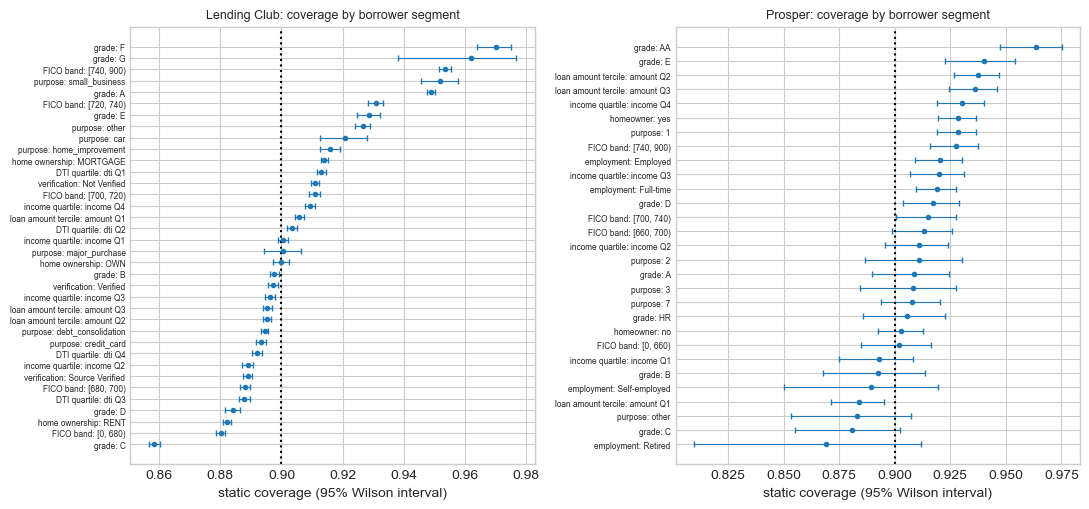

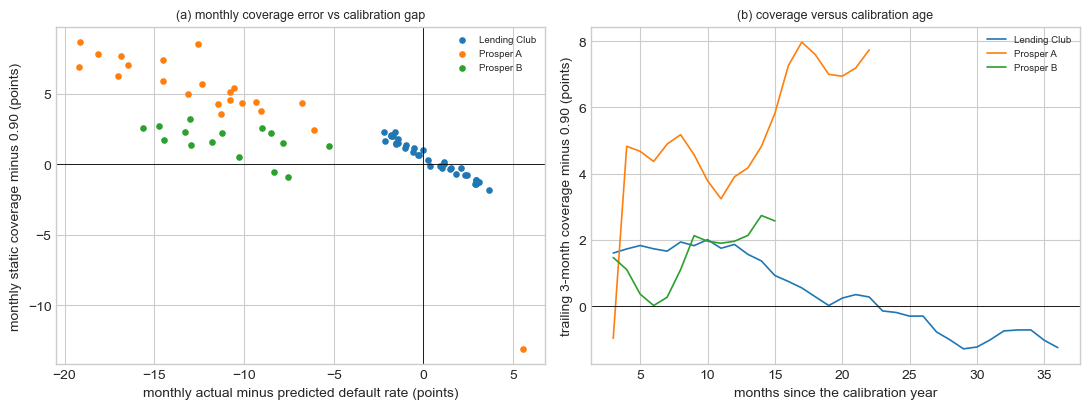

[figures: 2s | total 2.3 min]


In [20]:
with section('figures'):
    fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
    for a_, (port, dk) in zip(ax, (('Lending Club', '-'), ('Prosper', 'B'))):
        t = E1[(E1.portfolio == port) & (E1.design == dk)].reset_index(drop=True); t['lab'] = t['segment'] + ': ' + t['value']; t = t.sort_values('static_cov').reset_index(drop=True)
        a_.errorbar(t['static_cov'], range(len(t)), xerr=[t['static_cov'] - t['ci_lo'], t['ci_hi'] - t['static_cov']], fmt='o', ms=3, capsize=2, lw=0.8); a_.axvline(0.9, c='k', ls=':'); a_.set_yticks(range(len(t))); a_.set_yticklabels(t['lab'], fontsize=6); a_.set_xlabel('static coverage (95% Wilson interval)'); a_.set_title(f'{port}: coverage by borrower segment', fontsize=9)
    plt.tight_layout(); savefig('E1_segment_coverage'); plt.show()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    for (port, dk), d in E2M.groupby(['portfolio', 'design']): ax[0].scatter(100 * d['gap'], 100 * (d['cov'] - 0.9), s=14, label=f'{port} {dk}'.replace(' -', ''))
    ax[0].axhline(0, c='k', lw=0.6); ax[0].axvline(0, c='k', lw=0.6); ax[0].set_xlabel('monthly actual minus predicted default rate (points)'); ax[0].set_ylabel('monthly static coverage minus 0.90 (points)'); ax[0].legend(fontsize=7, frameon=False); ax[0].set_title('(a) monthly coverage error vs calibration gap', fontsize=9)
    for (port, dk), d in E2M.groupby(['portfolio', 'design']): ax[1].plot(d['months_since_cal'], 100 * (d['cov_trail'] - 0.9), lw=1.2, label=f'{port} {dk}'.replace(' -', ''))
    ax[1].axhline(0, c='k', lw=0.6); ax[1].set_xlabel('months since the calibration year'); ax[1].set_ylabel('trailing 3-month coverage minus 0.90 (points)'); ax[1].set_title('(b) coverage versus calibration age', fontsize=9); ax[1].legend(fontsize=7, frameon=False)
    plt.tight_layout(); savefig('E2_E3_monitoring_and_age'); plt.show()

In [21]:
lines = [f"EXTENSIONS SUMMARY ({time.strftime('%Y-%m-%d %H:%M')}), failed sections: {FAILED or 'none'}", "", "## E1 segment coverage", E1.round(4).to_string(index=False), "", "## E1b group-conditional fix", E1G.round(4).to_string(index=False), "", "## E2 monitoring", E2S.round(4).T.to_string(), "", "## E3 calibration age", E3.round(4).to_string(index=False)]
(OUT/'extensions_summary.txt').write_text("\n".join(lines)); print(f"FAILED SECTIONS: {FAILED or 'none'}"); print("Send me this file:", shutil.make_archive(str(Q2/'outputs_extensions'), 'zip', OUT))

FAILED SECTIONS: none
Send me this file: /Users/author/Desktop/Q2/outputs_extensions.zip
